# Image Classification

Comparing MLP, CNN, and ResNet18 models on facial and skin-lesion images.

## Datasets and Data Loaders

Place both dataset folders beside the notebook and use the project directory as the working directory. The labeled `test` folders serve as validation sets.


In [2]:
import os
import random
import numpy as np
import torch
from pathlib import Path
from datetime import datetime

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()

RUNS_DIR = Path("runs") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUNS_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
for folder in ("vai-de-pielea-mea", "you-re-on-candid-camera"):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Missing dataset folder: {folder}. Open the notebook from the project directory.")


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class ImageFolderDataset(Dataset):
	def __init__(self, root_dir, transform=None, class_to_idx=None):

		self.samples = []
		self.transform = transform

		classes = sorted(c for c in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, c)))
		self.class_to_idx = dict(class_to_idx) if class_to_idx is not None else {c: i for i, c in enumerate(classes)}
		if set(classes) - set(self.class_to_idx):
			raise ValueError("Unknown validation classes")
		self.classes = sorted(self.class_to_idx, key=self.class_to_idx.get)
		for c in classes:
			cls_dir = os.path.join(root_dir, c)
			for fname in sorted(os.listdir(cls_dir)):
				if not fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):
					continue
				self.samples.append((os.path.join(cls_dir, fname), self.class_to_idx[c]))
	def __len__(self):
		return len(self.samples)
	def __getitem__(self, idx):

		path, label = self.samples[idx]
		img = Image.open(path).convert("RGB")
		if self.transform is not None:

			img = self.transform(img)
		return img, label


In [5]:
import pandas as pd
from torch.utils.data import Dataset
from PIL import Image
import os

class MoleDataset(Dataset):
    def __init__(self, root_dir, csv_path, transform=None, class_to_idx=None):
        self.root_dir = root_dir
        self.data = pd.read_csv(csv_path)
        self.transform = transform

        self.class_to_idx = dict(class_to_idx) if class_to_idx is not None else {
            c: i for i, c in enumerate(sorted(self.data["diagnostic"].unique()))
        }
        if set(self.data["diagnostic"].unique()) - set(self.class_to_idx):
            raise ValueError("Unknown validation classes")
        self.classes = sorted(self.class_to_idx, key=self.class_to_idx.get)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        img_path = os.path.join(self.root_dir, row["imagine"])
        label = self.class_to_idx[row["diagnostic"]]

        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, label


In [6]:
from torchvision import transforms

basic_transform = transforms.Compose([
 transforms.Resize((64, 64)),
 transforms.ToTensor(),
 transforms.Normalize(mean=[0.5]*3, std=[0.5]*3),
])
train_set_cam = ImageFolderDataset("you-re-on-candid-camera/DATASET/train", transform=basic_transform)
val_set_cam = ImageFolderDataset("you-re-on-candid-camera/DATASET/test", transform=basic_transform,
    class_to_idx=train_set_cam.class_to_idx)

train_set_mole = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=basic_transform
)

val_set_mole = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=basic_transform,
    class_to_idx=train_set_mole.class_to_idx
)

train_loader_cam = DataLoader(train_set_cam, batch_size=64, shuffle=True, num_workers=0)
val_loader_cam = DataLoader(val_set_cam, batch_size=64, shuffle=False, num_workers=0)

train_loader_mole = DataLoader(train_set_mole, batch_size=64, shuffle=True, num_workers=0)
val_loader_mole = DataLoader(val_set_mole, batch_size=64, shuffle=False, num_workers=0)


## Models and Optimization


In [7]:
import torch.nn as nn
import torch.optim as optim

class SimpleMLP(nn.Module):
	def __init__(self, num_classes):
		super().__init__()
		self.net = nn.Sequential(
		 nn.Flatten(),
		 nn.Linear(3*64*64, 512),
		 nn.ReLU(inplace=True),
		 nn.Dropout(0.3),
		 nn.Linear(512, num_classes),
		)
	def forward(self, x):
		return self.net(x)
device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed()
model = SimpleMLP(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)


## Training and Evaluation


In [8]:
def train_one_epoch(model, loader, criterion, optimizer, device):

	model.train()
	for module in model.modules():
		if isinstance(module, nn.modules.batchnorm._BatchNorm):
			if not any(p.requires_grad for p in module.parameters()):
				module.eval()
	running_loss, correct, total = 0.0, 0, 0
	loss_weight = 0.0
	for images, labels in loader:
		images, labels = images.to(device), labels.to(device)

		optimizer.zero_grad()

		logits = model(images)

		loss = criterion(logits, labels)

		loss.backward()

		optimizer.step()

		batch_weight = labels.size(0) if criterion.weight is None else criterion.weight[labels].sum().item()
		running_loss += loss.item() * batch_weight
		loss_weight += batch_weight
		preds = logits.argmax(dim=1)
		correct += (preds == labels).sum().item()
		total += labels.size(0)

	return running_loss / loss_weight, correct / total


In [9]:
from sklearn.metrics import f1_score
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss, correct, total = 0.0, 0, 0
    loss_weight = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_weight = labels.size(0) if criterion.weight is None else criterion.weight[labels].sum().item()
        running_loss += loss.item() * batch_weight
        loss_weight += batch_weight

        preds = logits.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = correct / total

    f1_macro = f1_score(all_labels, all_preds, average="macro", labels=list(range(7)), zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average="micro", labels=list(range(7)), zero_division=0)

    return running_loss / loss_weight, acc, f1_macro, f1_micro


In [10]:
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime

run_name = f"mlp_lr1e-3_bs64_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
writer = SummaryWriter(log_dir=str(RUNS_DIR / run_name))


In [11]:
def run_training(model, train_loader, val_loader, criterion, optimizer, device, writer,
                 num_epochs=20, save_path="best_model.pt"):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1_macro": [],
        "val_f1_micro": []
    }

    best_val_loss = float("inf")
    best_epoch = 0

    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1_macro, va_f1_micro = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_f1_macro"].append(va_f1_macro)
        history["val_f1_micro"].append(va_f1_micro)

        writer.add_scalar("Loss/train", tr_loss, epoch)
        writer.add_scalar("Loss/val", va_loss, epoch)
        writer.add_scalar("Accuracy/train", tr_acc, epoch)
        writer.add_scalar("Accuracy/val", va_acc, epoch)
        writer.add_scalar("F1_macro/val", va_f1_macro, epoch)
        writer.add_scalar("F1_micro/val", va_f1_micro, epoch)
        writer.add_scalar("LR", optimizer.param_groups[0]["lr"], epoch)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), save_path)

        print(
            f"Epoch {epoch+1:02d} | "
            f"train loss={tr_loss:.4f} acc={tr_acc:.3f} | "
            f"val loss={va_loss:.4f} acc={va_acc:.3f} | "
            f"F1-macro={va_f1_macro:.3f} | "
            f"F1-micro={va_f1_micro:.3f}"
        )

    writer.close()
    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    model.eval()
    print(f"Reloaded checkpoint from epoch {best_epoch} (minimum validation loss).")

    import matplotlib.pyplot as plt

    plt.figure(figsize=(6, 4))
    plt.plot(history["train_loss"], label="train")
    plt.plot(history["val_loss"], label="val")
    plt.title("Loss")
    plt.xlabel("Epoca")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(history["train_acc"], label="train")
    plt.plot(history["val_acc"], label="val")
    plt.title("Accuracy")
    plt.xlabel("Epoca")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(history["val_f1_macro"], label="val F1-macro")
    plt.title("F1-macro")
    plt.xlabel("Epoca")
    plt.ylabel("F1-macro")
    plt.legend()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(history["val_f1_micro"], label="val F1-micro")
    plt.title("F1-micro")
    plt.xlabel("Epoca")
    plt.ylabel("F1-micro")
    plt.legend()
    plt.show()

    return history


Epoch 01 | train loss=1.5581 acc=0.514 | val loss=1.2701 acc=0.573 | F1-macro=0.422 | F1-micro=0.573
Epoch 02 | train loss=1.2072 acc=0.587 | val loss=1.0950 acc=0.626 | F1-macro=0.477 | F1-micro=0.626
Epoch 03 | train loss=1.1314 acc=0.615 | val loss=1.0958 acc=0.614 | F1-macro=0.490 | F1-micro=0.614
Epoch 04 | train loss=1.0763 acc=0.635 | val loss=1.0572 acc=0.634 | F1-macro=0.521 | F1-micro=0.634
Epoch 05 | train loss=1.0328 acc=0.645 | val loss=1.0317 acc=0.642 | F1-macro=0.514 | F1-micro=0.642
Epoch 06 | train loss=1.0139 acc=0.654 | val loss=1.1040 acc=0.628 | F1-macro=0.495 | F1-micro=0.628
Epoch 07 | train loss=1.0170 acc=0.656 | val loss=1.0284 acc=0.655 | F1-macro=0.520 | F1-micro=0.655
Epoch 08 | train loss=0.9906 acc=0.664 | val loss=1.0488 acc=0.658 | F1-macro=0.526 | F1-micro=0.658
Epoch 09 | train loss=0.9586 acc=0.671 | val loss=1.0851 acc=0.655 | F1-macro=0.536 | F1-micro=0.655
Epoch 10 | train loss=0.9411 acc=0.683 | val loss=1.0528 acc=0.654 | F1-macro=0.520 | F1-mi

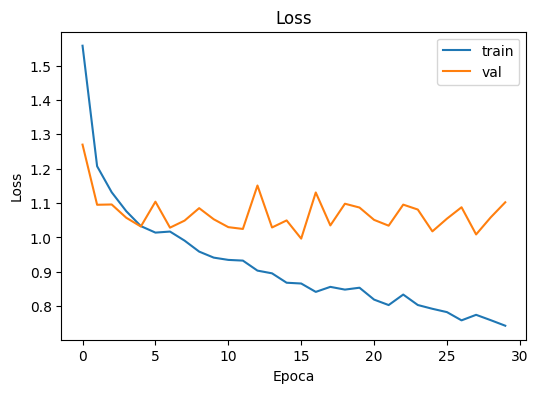

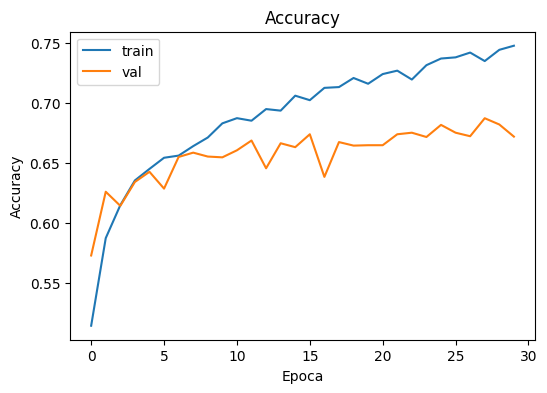

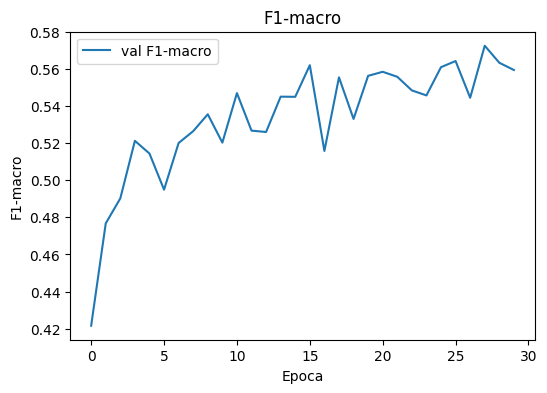

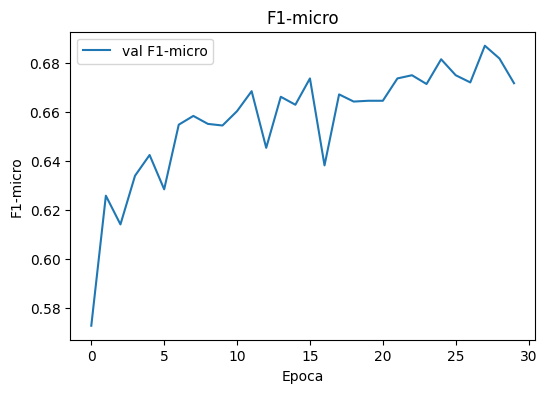

In [12]:
history_mlp_simple_cam = run_training(
    model,
    train_loader_cam,
    val_loader_cam,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="mlp_simple_cam.pt"
)


Epoch 01 | train loss=1.2042 acc=0.643 | val loss=0.9775 acc=0.673 | F1-macro=0.179 | F1-micro=0.673
Epoch 02 | train loss=0.9552 acc=0.682 | val loss=0.9381 acc=0.674 | F1-macro=0.147 | F1-micro=0.674
Epoch 03 | train loss=0.9060 acc=0.693 | val loss=0.9219 acc=0.696 | F1-macro=0.254 | F1-micro=0.696
Epoch 04 | train loss=0.9062 acc=0.683 | val loss=0.9096 acc=0.684 | F1-macro=0.190 | F1-micro=0.684
Epoch 05 | train loss=0.8571 acc=0.691 | val loss=0.9094 acc=0.698 | F1-macro=0.271 | F1-micro=0.698
Epoch 06 | train loss=0.8565 acc=0.697 | val loss=0.9106 acc=0.681 | F1-macro=0.225 | F1-micro=0.681
Epoch 07 | train loss=0.8448 acc=0.699 | val loss=0.9091 acc=0.688 | F1-macro=0.191 | F1-micro=0.688
Epoch 08 | train loss=0.8218 acc=0.709 | val loss=0.8966 acc=0.705 | F1-macro=0.292 | F1-micro=0.705
Epoch 09 | train loss=0.8286 acc=0.702 | val loss=0.9135 acc=0.692 | F1-macro=0.251 | F1-micro=0.692
Epoch 10 | train loss=0.8518 acc=0.701 | val loss=0.9029 acc=0.698 | F1-macro=0.283 | F1-mi

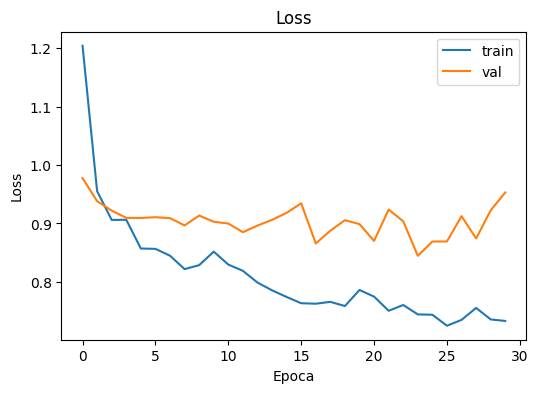

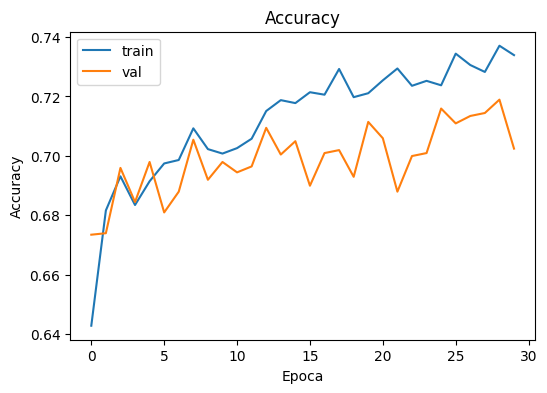

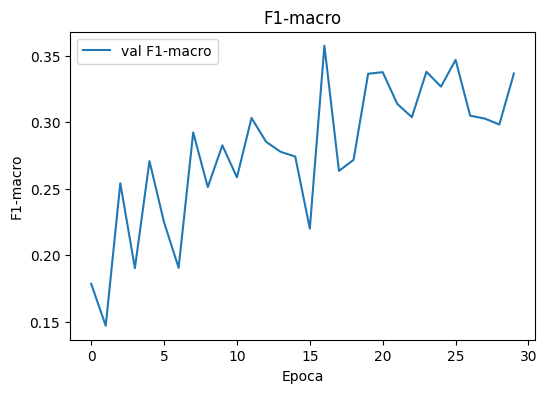

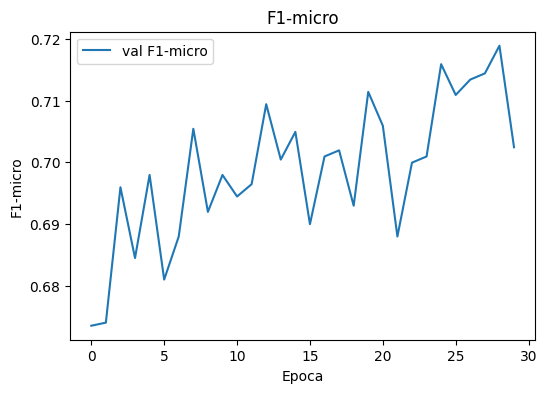

In [13]:
set_seed()
model = SimpleMLP(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "mlp_mole"))

history_mlp_mole = run_training(
    model,
    train_loader_mole,
    val_loader_mole,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="mlp_mole.pt"
)


### MLP Without Dropout — Faces


In [14]:
class SimpleMLP_NoDropout(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64 * 3, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)


Epoch 01 | train loss=1.4188 acc=0.542 | val loss=1.1795 acc=0.591 | F1-macro=0.471 | F1-micro=0.591
Epoch 02 | train loss=1.0783 acc=0.622 | val loss=1.1297 acc=0.616 | F1-macro=0.485 | F1-micro=0.616
Epoch 03 | train loss=0.9776 acc=0.663 | val loss=1.0483 acc=0.639 | F1-macro=0.521 | F1-micro=0.639
Epoch 04 | train loss=0.9370 acc=0.676 | val loss=1.0630 acc=0.629 | F1-macro=0.498 | F1-micro=0.629
Epoch 05 | train loss=0.8889 acc=0.692 | val loss=1.0470 acc=0.642 | F1-macro=0.516 | F1-micro=0.642
Epoch 06 | train loss=0.8346 acc=0.708 | val loss=1.0870 acc=0.631 | F1-macro=0.518 | F1-micro=0.631
Epoch 07 | train loss=0.7848 acc=0.728 | val loss=1.1143 acc=0.645 | F1-macro=0.525 | F1-micro=0.645
Epoch 08 | train loss=0.7789 acc=0.732 | val loss=1.0330 acc=0.654 | F1-macro=0.546 | F1-micro=0.654
Epoch 09 | train loss=0.7417 acc=0.745 | val loss=1.1294 acc=0.644 | F1-macro=0.541 | F1-micro=0.644
Epoch 10 | train loss=0.7202 acc=0.753 | val loss=1.2322 acc=0.629 | F1-macro=0.539 | F1-mi

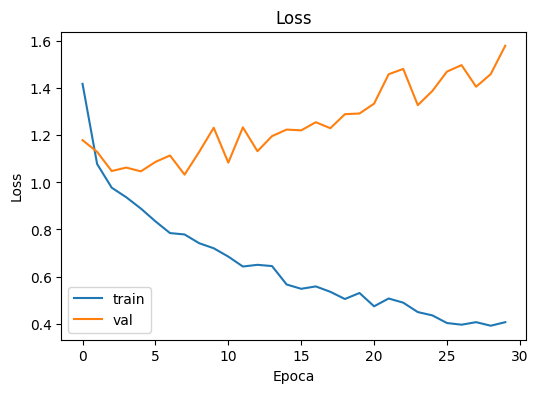

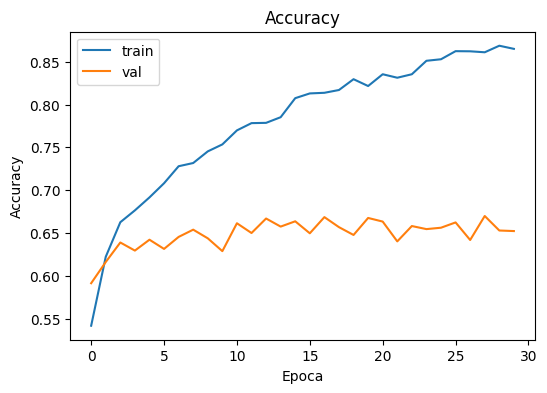

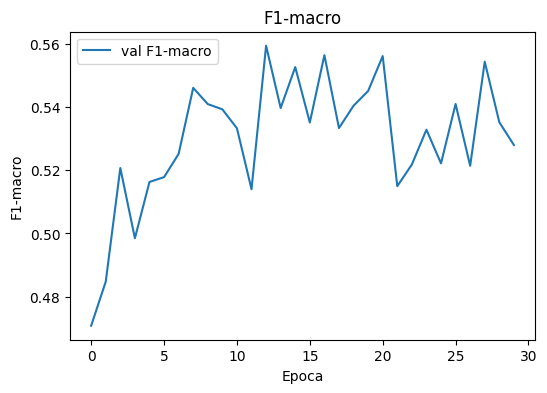

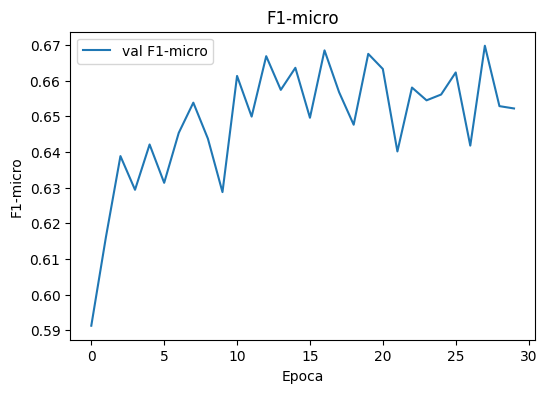

In [15]:
set_seed()
model = SimpleMLP_NoDropout(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "mlp_no_dropout_cam"))

history_mlp_no_dropout_cam = run_training(
    model=model,
    train_loader=train_loader_cam,
    val_loader=val_loader_cam,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    writer=writer,
    num_epochs=30,
    save_path="mlp_no_dropout_cam.pt"
)


### MLP Without Dropout — Skin Lesions


Epoch 01 | train loss=1.1489 acc=0.653 | val loss=0.9771 acc=0.689 | F1-macro=0.218 | F1-micro=0.689
Epoch 02 | train loss=0.9030 acc=0.687 | val loss=0.9087 acc=0.694 | F1-macro=0.247 | F1-micro=0.694
Epoch 03 | train loss=0.8444 acc=0.701 | val loss=0.8943 acc=0.697 | F1-macro=0.255 | F1-micro=0.697
Epoch 04 | train loss=0.8012 acc=0.709 | val loss=0.8791 acc=0.692 | F1-macro=0.250 | F1-micro=0.692
Epoch 05 | train loss=0.7760 acc=0.722 | val loss=0.8583 acc=0.708 | F1-macro=0.279 | F1-micro=0.708
Epoch 06 | train loss=0.7546 acc=0.728 | val loss=0.9357 acc=0.689 | F1-macro=0.324 | F1-micro=0.689
Epoch 07 | train loss=0.7285 acc=0.736 | val loss=0.8802 acc=0.708 | F1-macro=0.310 | F1-micro=0.708
Epoch 08 | train loss=0.7099 acc=0.737 | val loss=0.8316 acc=0.702 | F1-macro=0.346 | F1-micro=0.702
Epoch 09 | train loss=0.6975 acc=0.744 | val loss=0.8651 acc=0.700 | F1-macro=0.375 | F1-micro=0.700
Epoch 10 | train loss=0.6811 acc=0.750 | val loss=0.9220 acc=0.708 | F1-macro=0.352 | F1-mi

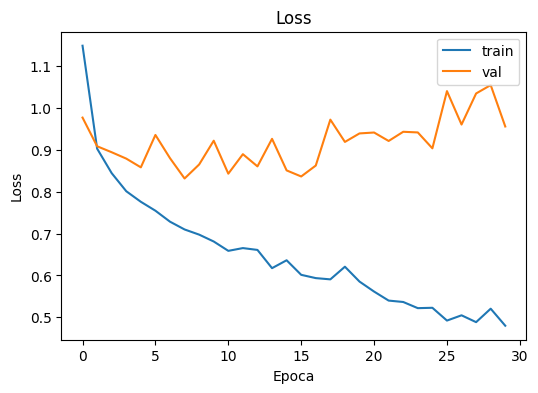

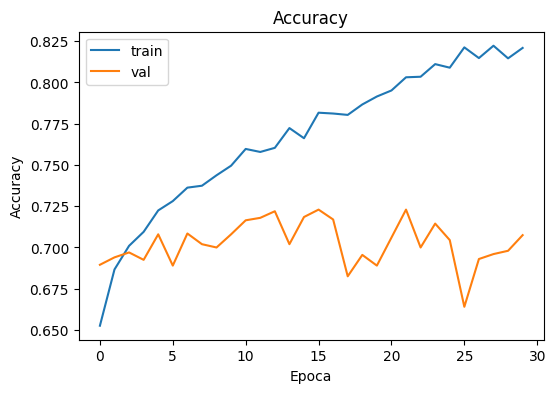

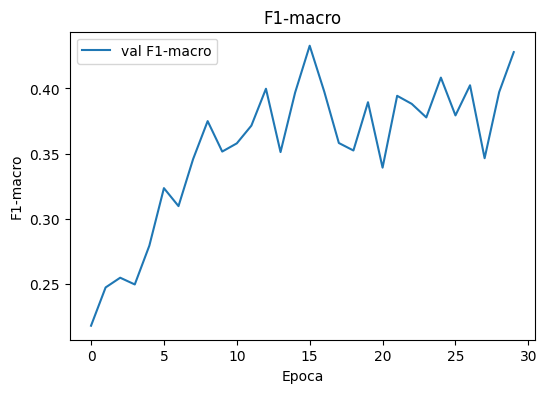

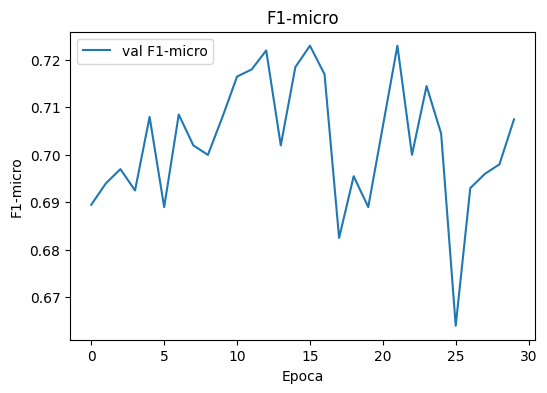

In [16]:
set_seed()
model = SimpleMLP_NoDropout(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "mlp_no_dropout_mole"))

history_mlp_no_dropout_mole = run_training(
    model=model,
    train_loader=train_loader_mole,
    val_loader=val_loader_mole,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    writer=writer,
    num_epochs=30,
    save_path="mlp_no_dropout_mole.pt"
)


## CNN Baseline


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)

device = "cuda" if torch.cuda.is_available() else "cpu"

set_seed()
model = SimpleCNN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


In [18]:
run_name = f"cnn_simple_lr1e-3_bs64_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
writer = SummaryWriter(log_dir=str(RUNS_DIR / run_name))


In [ ]:
history_cnn_simple_cam = run_training(
    model,
    train_loader_cam,
    val_loader_cam,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=90,
    save_path="cnn_simple_cam.pt"
)


In [ ]:
set_seed()
model = SimpleCNN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_mole"))

history_cnn_mole = run_training(
    model,
    train_loader_mole,
    val_loader_mole,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=90,
    save_path="cnn_mole.pt"
)


## CNN With Batch Normalization


In [ ]:
import torch.nn as nn
from torch.utils.data import DataLoader

class SimpleCNN_BN(nn.Module):
	def __init__(self, num_classes):
		super().__init__()
		self.features = nn.Sequential(

		 nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
		 nn.BatchNorm2d(32),
		 nn.ReLU(inplace=True),
		 nn.MaxPool2d(2),

		 nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
		 nn.BatchNorm2d(64),
		 nn.ReLU(inplace=True),
		 nn.MaxPool2d(2),

		 nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
		 nn.BatchNorm2d(128),
		 nn.ReLU(inplace=True),
		 nn.AdaptiveAvgPool2d(1),
		)
		self.classifier = nn.Linear(128, num_classes)
	def forward(self, x):
		x = self.features(x)
		x = x.flatten(1)
		return self.classifier(x)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)


In [ ]:
run_name = f"cnn_batch_norm_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
writer = SummaryWriter(log_dir=str(RUNS_DIR / run_name))


In [ ]:
history_cnn_bn_cam = run_training(
    model,
    train_loader_cam,
    val_loader_cam,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=90,
    save_path="cnn_bn_cam.pt"
)


In [ ]:
set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole"))

history_cnn_bn_mole = run_training(
    model,
    train_loader_mole,
    val_loader_mole,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=90,
    save_path="cnn_bn_mole.pt"
)


## Data Augmentation
### Skin-Lesion Preview


In [ ]:
import matplotlib.pyplot as plt
import torch

def denormalize(img):
    mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    std = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    img = img * std + mean
    return img.clamp(0, 1)

def show_original_and_augmented_per_class(original_dataset, augmented_dataset, class_names=None):
    seen_indices = {}

    for i in range(len(original_dataset)):
        _, label = original_dataset[i]

        if label not in seen_indices:
            seen_indices[label] = i

        if len(seen_indices) == 7:
            break

    fig, axes = plt.subplots(len(seen_indices), 2, figsize=(6, 3 * len(seen_indices)), squeeze=False)

    for row, (label, idx) in enumerate(seen_indices.items()):
        img_orig, _ = original_dataset[idx]
        img_aug, _ = augmented_dataset[idx]

        img_orig = denormalize(img_orig)
        img_aug = denormalize(img_aug)

        title = class_names[label] if class_names is not None else f"Class {label}"
        axes[row, 0].imshow(img_orig.permute(1, 2, 0))
        axes[row, 0].set_title(f"{title} - original")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img_aug.permute(1, 2, 0))
        axes[row, 1].set_title(f"{title} - augmented")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
  transforms.Resize((72, 72)),
  transforms.RandomCrop(64),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.ColorJitter(brightness=0.2,
                         contrast=0.2,
                         saturation=0.2),

  transforms.RandomRotation(degrees=15),
  transforms.ToTensor(),
  transforms.Normalize(mean=[0.5, 0.5, 0.5],
                       std=[0.5, 0.5, 0.5]),
])

val_transform = transforms.Compose([
  transforms.Resize((64, 64)),
  transforms.ToTensor(),
  transforms.Normalize(mean=[0.5, 0.5, 0.5],
                      std=[0.5, 0.5, 0.5]),
])


In [ ]:
mole_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_mole_aug = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=mole_train_transform
)

val_set_mole_aug = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=val_transform,
    class_to_idx=train_set_mole.class_to_idx
)


In [ ]:
import matplotlib.pyplot as plt

img, label = train_set_mole_aug[0]

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for ax in axes:
    img_aug, _ = train_set_mole_aug[0]
    ax.imshow(img_aug.permute(1, 2, 0) * 0.5 + 0.5)
    ax.axis("off")

plt.show()


In [ ]:
show_original_and_augmented_per_class(
    train_set_mole,
    train_set_mole_aug,
    class_names=train_set_mole_aug.classes
)


### Facial-Image Preview


In [ ]:
cam_train_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

cam_val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])


In [ ]:
train_set_cam_aug = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=cam_train_transform
)

val_set_cam_aug = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=cam_val_transform,
    class_to_idx=train_set_cam.class_to_idx
)


In [ ]:
import matplotlib.pyplot as plt

img, label = train_set_cam_aug[0]

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for ax in axes:
    img_aug, _ = train_set_cam_aug[0]
    ax.imshow(img_aug.permute(1, 2, 0) * 0.5 + 0.5)
    ax.axis("off")

plt.show()


In [ ]:
idx_to_class_cam = {v: k for k, v in train_set_cam_aug.class_to_idx.items()}

show_original_and_augmented_per_class(
    train_set_cam,
    train_set_cam_aug,
    class_names=idx_to_class_cam
)


## No-Augmentation Baselines — 30 Epochs


In [ ]:
train_loader_cam_no_aug = DataLoader(
    train_set_cam,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_cam_no_aug = DataLoader(
    val_set_cam,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_cam_no_aug"))

history_cnn_bn_cam_no_aug = run_training(
    model,
    train_loader_cam_no_aug,
    val_loader_cam_no_aug,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_cam_no_aug.pt"
)


In [ ]:
train_loader_mole_no_aug = DataLoader(
    train_set_mole,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_mole_no_aug = DataLoader(
    val_set_mole,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole_no_aug"))

history_cnn_bn_mole_no_aug = run_training(
    model,
    train_loader_mole_no_aug,
    val_loader_mole_no_aug,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_mole_no_aug.pt"
)


### Faces — Geometric Augmentation


In [ ]:
cam_geom_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_cam_geom = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=cam_geom_transform
)

val_set_cam_geom = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=cam_val_transform,
    class_to_idx=train_set_cam.class_to_idx
)

train_loader_cam_geom = DataLoader(
    train_set_cam_geom,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_cam_geom = DataLoader(
    val_set_cam_geom,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_cam_geom_aug"))

history_cnn_bn_cam_geom = run_training(
    model,
    train_loader_cam_geom,
    val_loader_cam_geom,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_cam_geom_aug.pt"
)


### Faces — Color Augmentation


In [ ]:
cam_color_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_cam_color = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=cam_color_transform
)

val_set_cam_color = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=cam_val_transform,
    class_to_idx=train_set_cam.class_to_idx
)

train_loader_cam_color = DataLoader(
    train_set_cam_color,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_cam_color = DataLoader(
    val_set_cam_color,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_cam_color_aug"))

history_cnn_bn_cam_color = run_training(
    model,
    train_loader_cam_color,
    val_loader_cam_color,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_cam_color_aug.pt"
)


### Faces — Combined Augmentation


In [ ]:
cam_all_aug_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_cam_all_aug = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=cam_all_aug_transform
)

val_set_cam_all_aug = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=cam_val_transform,
    class_to_idx=train_set_cam.class_to_idx
)

train_loader_cam_all_aug = DataLoader(
    train_set_cam_all_aug,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_cam_all_aug = DataLoader(
    val_set_cam_all_aug,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_cam_all_aug"))

history_cnn_bn_cam_all_aug = run_training(
    model,
    train_loader_cam_all_aug,
    val_loader_cam_all_aug,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_cam_all_aug.pt"
)


### Skin Lesions — Geometric Augmentation


In [ ]:
mole_geom_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_mole_geom = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=mole_geom_transform
)

val_set_mole_geom = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=val_transform,
    class_to_idx=train_set_mole.class_to_idx
)

train_loader_mole_geom = DataLoader(
    train_set_mole_geom,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_mole_geom = DataLoader(
    val_set_mole_geom,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole_geom_aug"))

history_cnn_bn_mole_geom = run_training(
    model,
    train_loader_mole_geom,
    val_loader_mole_geom,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_mole_geom_aug.pt"
)


### Skin Lesions — Color Augmentation


In [ ]:
mole_color_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.01
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_mole_color = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=mole_color_transform
)

val_set_mole_color = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=val_transform,
    class_to_idx=train_set_mole.class_to_idx
)

train_loader_mole_color = DataLoader(
    train_set_mole_color,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_mole_color = DataLoader(
    val_set_mole_color,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole_color_aug"))

history_cnn_bn_mole_color = run_training(
    model,
    train_loader_mole_color,
    val_loader_mole_color,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_mole_color_aug.pt"
)


### Skin Lesions — Combined Augmentation


In [ ]:
mole_all_aug_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),

    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.01
    ),

    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

train_set_mole_all_aug = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=mole_all_aug_transform
)

val_set_mole_all_aug = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=val_transform,
    class_to_idx=train_set_mole.class_to_idx
)

train_loader_mole_all_aug = DataLoader(
    train_set_mole_all_aug,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader_mole_all_aug = DataLoader(
    val_set_mole_all_aug,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole_all_aug"))

history_cnn_bn_mole_all_aug = run_training(
    model,
    train_loader_mole_all_aug,
    val_loader_mole_all_aug,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_mole_all_aug.pt"
)


## Class Imbalance — Weighted Sampling


In [ ]:
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler, DataLoader

labels = train_set_mole.data["diagnostic"].map(train_set_mole.class_to_idx).to_numpy()

class_counts = np.bincount(labels)
print("Class distribution:", class_counts)

class_weights = 1.0 / class_counts
sample_weights = class_weights[labels]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

balanced_train_loader_mole = DataLoader(
    train_set_mole,
    batch_size=64,
    sampler=sampler,
    num_workers=2
)

set_seed()
model = SimpleCNN_BN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "cnn_bn_mole_balanced_sampler"))

history_cnn_bn_mole_balanced = run_training(
    model,
    balanced_train_loader_mole,
    val_loader_mole,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=30,
    save_path="cnn_bn_mole_balanced_sampler.pt"
)


## ResNet18 — Classifier Training


In [ ]:
from torchvision import models, transforms
import torch.nn as nn
import torch
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR

finetune_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

finetune_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


In [ ]:
train_set_cam_ft = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=finetune_train_transform
)

val_set_cam_ft = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=finetune_val_transform,
    class_to_idx=train_set_cam.class_to_idx
)

train_loader_cam_ft = DataLoader(train_set_cam_ft, batch_size=32, shuffle=True, num_workers=2)
val_loader_cam_ft = DataLoader(val_set_cam_ft, batch_size=32, shuffle=False, num_workers=2)


In [ ]:
train_set_mole_ft = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=finetune_train_transform
)

val_set_mole_ft = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=finetune_val_transform,
    class_to_idx=train_set_mole.class_to_idx
)

train_loader_mole_ft = DataLoader(train_set_mole_ft, batch_size=32, shuffle=True, num_workers=2)
val_loader_mole_ft = DataLoader(val_set_mole_ft, batch_size=32, shuffle=False, num_workers=2)


In [ ]:
def create_resnet18_frozen(num_classes=7):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    for param in model.parameters():
        param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    return model.to(device)


## Learning Rate Warmup


In [ ]:
def run_training_with_scheduler(model, train_loader, val_loader, criterion, optimizer, scheduler, device, writer,
                                num_epochs=10, save_path="best_model.pt"):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1_macro": [],
        "val_f1_micro": []
    }

    best_val_loss = float("inf")
    best_epoch = 0

    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1_macro, va_f1_micro = evaluate(model, val_loader, criterion, device)

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_f1_macro"].append(va_f1_macro)
        history["val_f1_micro"].append(va_f1_micro)

        writer.add_scalar("Loss/train", tr_loss, epoch)
        writer.add_scalar("Loss/val", va_loss, epoch)
        writer.add_scalar("Accuracy/train", tr_acc, epoch)
        writer.add_scalar("Accuracy/val", va_acc, epoch)
        writer.add_scalar("F1_macro/val", va_f1_macro, epoch)
        writer.add_scalar("F1_micro/val", va_f1_micro, epoch)
        writer.add_scalar("LR", current_lr, epoch)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), save_path)

        print(
            f"Epoch {epoch+1:02d} | "
            f"train loss={tr_loss:.4f} acc={tr_acc:.3f} | "
            f"val loss={va_loss:.4f} acc={va_acc:.3f} | "
            f"F1-macro={va_f1_macro:.3f} | "
            f"LR={current_lr:.6f}"
        )

        scheduler.step()

    writer.close()
    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    model.eval()
    print(f"Reloaded checkpoint from epoch {best_epoch} (minimum validation loss).")
    return history


In [ ]:
set_seed()
model = create_resnet18_frozen(num_classes=7)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "finetune_resnet18_mole_no_warmup"))

history_ft_mole_no_warmup = run_training(
    model,
    train_loader_mole_ft,
    val_loader_mole_ft,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=10,
    save_path="finetune_resnet18_mole_no_warmup.pt"
)


In [ ]:
set_seed()
model = create_resnet18_frozen(num_classes=7)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "finetune_resnet18_cam_no_warmup"))

history_ft_cam_no_warmup = run_training(
    model,
    train_loader_cam_ft,
    val_loader_cam_ft,
    criterion,
    optimizer,
    device,
    writer,
    num_epochs=10,
    save_path="finetune_resnet18_cam_no_warmup.pt"
)


In [ ]:
set_seed()
model = create_resnet18_frozen(num_classes=7)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

warmup_epochs = 3
total_epochs = 10

scheduler = LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: min(1.0, (epoch + 1) / warmup_epochs)
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "finetune_resnet18_mole_warmup"))

history_ft_mole_warmup = run_training_with_scheduler(
    model,
    train_loader_mole_ft,
    val_loader_mole_ft,
    criterion,
    optimizer,
    scheduler,
    device,
    writer,
    num_epochs=total_epochs,
    save_path="finetune_resnet18_mole_warmup.pt"
)


In [ ]:
set_seed()
model = create_resnet18_frozen(num_classes=7)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)

warmup_epochs = 3
total_epochs = 10

scheduler = LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: min(1.0, (epoch + 1) / warmup_epochs)
)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "finetune_resnet18_cam_warmup"))

history_ft_cam_warmup = run_training_with_scheduler(
    model,
    train_loader_cam_ft,
    val_loader_cam_ft,
    criterion,
    optimizer,
    scheduler,
    device,
    writer,
    num_epochs=10,
    save_path="finetune_resnet18_cam_warmup.pt"
)


## Additional Skin-Lesion Fine-Tuning


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.tensorboard import SummaryWriter

ft_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

ft_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_set = MoleDataset(
    root_dir="vai-de-pielea-mea/train",
    csv_path="vai-de-pielea-mea/train.csv",
    transform=ft_train_transform
)

val_set = MoleDataset(
    root_dir="vai-de-pielea-mea/test",
    csv_path="vai-de-pielea-mea/test.csv",
    transform=ft_val_transform,
    class_to_idx=train_set_mole.class_to_idx
)

labels = train_set.data["diagnostic"].map(train_set.class_to_idx).to_numpy()
class_counts = np.bincount(labels)
print("Class distribution:", dict(zip(train_set.classes, class_counts)))

sample_weights = (1.0 / class_counts)[labels]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(train_set, batch_size=32, sampler=sampler, num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=32, shuffle=False,    num_workers=2)

set_seed()
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False

for name, param in model.named_parameters():
    if "layer4" in name or "fc" in name:
        param.requires_grad = True

model.fc = nn.Linear(model.fc.in_features, 7)
model = model.to(device)

class_weights = torch.tensor(1.0 / class_counts, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-4)

NUM_EPOCHS = 40
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

writer = SummaryWriter(log_dir=str(RUNS_DIR / "resnet18_mole_improved"))

history = run_training_with_scheduler(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    writer,
    num_epochs=NUM_EPOCHS,
    save_path="resnet18_mole_improved.pt"
)

model.load_state_dict(torch.load("resnet18_mole_improved.pt", map_location=device, weights_only=True))
model.eval()
print("Best checkpoint loaded.")


## Additional Facial-Image Fine-Tuning


In [ ]:
from torchvision import models, transforms
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

cam_train_transform_v2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

cam_val_transform_v2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

train_set_cam_v2 = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/train",
    transform=cam_train_transform_v2
)

val_set_cam_v2 = ImageFolderDataset(
    "you-re-on-candid-camera/DATASET/test",
    transform=cam_val_transform_v2,
    class_to_idx=train_set_cam.class_to_idx
)

train_loader_cam_v2 = DataLoader(
    train_set_cam_v2,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader_cam_v2 = DataLoader(
    val_set_cam_v2,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

set_seed()
model_cam_v2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model_cam_v2.parameters():
    param.requires_grad = False

model_cam_v2.fc = nn.Linear(model_cam_v2.fc.in_features, 7)

for param in model_cam_v2.layer4.parameters():
    param.requires_grad = True

for param in model_cam_v2.fc.parameters():
    param.requires_grad = True

model_cam_v2 = model_cam_v2.to(device)

optimizer_cam_v2 = torch.optim.Adam([
    {"params": model_cam_v2.layer4.parameters(), "lr": 1e-4},
    {"params": model_cam_v2.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-4)

criterion_cam_v2 = nn.CrossEntropyLoss()

writer_cam_v2 = SummaryWriter(log_dir=str(RUNS_DIR / "resnet18_cam_layer4_unfrozen"))

history_cam_v2 = run_training(
    model_cam_v2,
    train_loader_cam_v2,
    val_loader_cam_v2,
    criterion_cam_v2,
    optimizer_cam_v2,
    device,
    writer_cam_v2,
    num_epochs=25,
    save_path="resnet18_cam_layer4_unfrozen.pt"
)

model_cam_v2.load_state_dict(
    torch.load("resnet18_cam_layer4_unfrozen.pt", map_location=device, weights_only=True)
)
model_cam_v2.eval()

print("Best facial-image checkpoint loaded.")


## Skin-Lesion Prediction Export


In [ ]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import torch

class MoleKaggleDataset(Dataset):
    def __init__(self, root_dir, csv_path, transform=None):
        self.root_dir = root_dir
        self.data = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        img_name = row["imagine"]
        img_path = os.path.join(self.root_dir, img_name)

        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, img_name


In [ ]:
kaggle_set_mole = MoleKaggleDataset(
    root_dir="vai-de-pielea-mea/kaggle_test",
    csv_path="vai-de-pielea-mea/kaggle_test.csv",
    transform=finetune_val_transform
)

kaggle_loader_mole = DataLoader(
    kaggle_set_mole,
    batch_size=64,
    shuffle=False,
    num_workers=2
)


In [ ]:
set_seed()
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 7)
model = model.to(device)
model.load_state_dict(torch.load("resnet18_mole_improved.pt", map_location=device, weights_only=True))
model.eval()


In [ ]:
idx_to_class = {index: name for name, index in train_set_mole.class_to_idx.items()}
print("Skin-label encoding:", idx_to_class)

predictions = []

with torch.no_grad():
    for images, img_names in kaggle_loader_mole:
        images = images.to(device)

        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()

        for img_name, pred in zip(img_names, preds):
            predictions.append({
                "Id": img_name,
                "Prediction": int(pred)
            })

submission = pd.DataFrame(predictions)

submission.to_csv("submission_mole.csv", index=False)

submission.head()


## Facial-Image Prediction Export


In [ ]:
class CamKaggleDataset(Dataset):
    def __init__(self, root_dir, csv_path, transform=None):
        self.root_dir = root_dir
        self.data = pd.read_csv(csv_path)
        self.transform = transform

        self.image_paths = {}
        for dirpath, _, filenames in os.walk(root_dir):
            for fname in filenames:
                if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    if fname in self.image_paths:
                        raise ValueError(f"Duplicate image filename: {fname}")
                    self.image_paths[fname] = os.path.join(dirpath, fname)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_name = row["id"]

        img_path = self.image_paths[img_name]

        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, img_name


In [ ]:
kaggle_set_cam = CamKaggleDataset(
    root_dir="you-re-on-candid-camera/DATASET/test",
    csv_path="you-re-on-candid-camera/splits/remote_test.csv",
    transform=cam_val_transform_v2
)

kaggle_loader_cam = DataLoader(
    kaggle_set_cam,
    batch_size=64,
    shuffle=False,
    num_workers=0
)


In [ ]:
model_submission_cam = models.resnet18(weights=None)
model_submission_cam.fc = nn.Linear(model_submission_cam.fc.in_features, 7)
for param in model_submission_cam.layer4.parameters():
    param.requires_grad = True
model_submission_cam = model_submission_cam.to(device)

model_submission_cam.load_state_dict(
    torch.load("resnet18_cam_layer4_unfrozen.pt", map_location=device, weights_only=True)
)
model_submission_cam.eval()


In [ ]:
predictions = []

with torch.no_grad():
    for images, labels in kaggle_loader_cam:
        images = images.to(device)

        logits = model_submission_cam(images)
        preds = logits.argmax(dim=1).cpu().numpy()

        for img_name, pred in zip(labels, preds):
            predictions.append({
                "Id": img_name,
                "label": int(pred) + 1
            })

submission_cam = pd.DataFrame(predictions)
submission_cam.to_csv("submission_cam.csv", index=False)
submission_cam.head()


## Validation Summary

Metrics correspond to the checkpoint with the lowest validation loss for each experiment.


In [ ]:
summary_rows = []
for name, value in list(globals().items()):
    if name.startswith("history") and isinstance(value, dict) and "val_loss" in value:
        best = int(np.argmin(value["val_loss"]))
        summary_rows.append({
            "experiment": name,
            "best_epoch": best + 1,
            "validation_loss": value["val_loss"][best],
            "accuracy": value["val_acc"][best],
            "macro_f1": value["val_f1_macro"][best],
            "micro_f1": value["val_f1_micro"][best],
        })
summary = pd.DataFrame(summary_rows)
display(summary)
summary.to_csv("validation_summary.csv", index=False)
